In [46]:
import numpy as np
import matplotlib.pyplot as plt

In [47]:
def newton_raphson(f, df, x0, tol=0.5e-6, max_iter=100):
  """
  Implements the Newton-Raphson Method to find the root of f(x)=0.

  Parameters:
    f (function): The function for which the root is to be found.
    df (function): The derivative of the function.
    x0 (float): Initial Guess.
    tol (float): Tolerance for the stopping criterion.
    max_iter (int): Maximum number of iterations.

  Returns:
    root (float): The approximated root.
    error_table (list): A table of iterations, root approximations, and errors.
  """
  error_table = []
  for iteration in range(1, max_iter+1):
    # Compute the root approximation using the formula
    fx=f(x0)
    dfx=df(x0)
    if dfx == 0:
      raise ZeroDivisionError("Derivative is zero. Method fails.")
    x1 = x0-fx/dfx    # Newton-Raphson Formula
    error = abs(x1-x0)
    # Store iteration details
    error_table.append((iteration, x1, error))
    # Check for convergence
    if error < tol or abs(f(x1)) < tol:
      return x1, error_table
    # Update the interval
    x0 = x1
  raise RuntimeError("Maximum iterations exceeded without convergence.")

In [48]:
# Define the function and its derivate
def f(x):
  # return x**2-4
  # return x**3-2*x-8    # x^3-2x-8
  return x**2-np.cos(x)

In [49]:
def df(x):
  # return 2*x
  # return 3*x**2-2
  return 2*x+np.sin(x)

In [50]:
# Initial guesses
x0 = 4

In [51]:
# Find the root and generate the error table
root, error_table = newton_raphson(f, df, x0)

In [52]:
# Print the error table
print("Iteration\tRoot Approximation\tError")
for iteration, x1, error in error_table:
  print(f"{iteration}\t{x1:.6f}\t\t{error:.6e}")

Iteration	Root Approximation	Error
1	1.700788		2.299212e+00
2	1.012828		6.879607e-01
3	0.840121		1.727064e-01
4	0.824273		1.584823e-02
5	0.824132		1.407997e-04


In [53]:
# Plot the convergence
iterations = [row[0] for row in error_table]
errors = [row[2] for row in error_table]

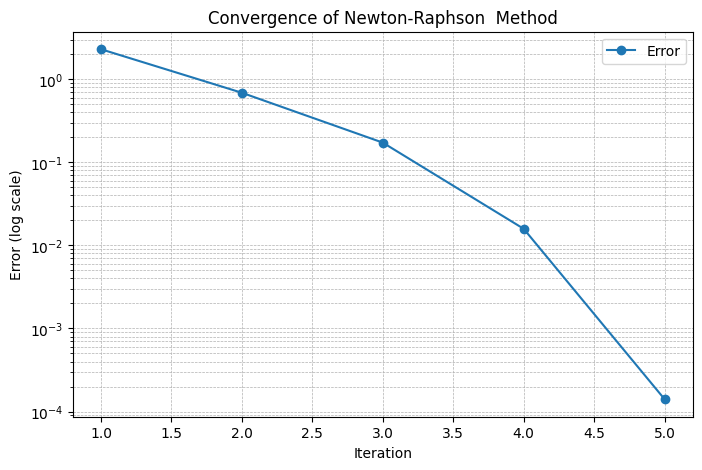

In [54]:
plt.figure(figsize=(8, 5))
plt.plot(iterations, errors, marker='o', label='Error')
plt.yscale('log')
plt.xlabel('Iteration')
plt.ylabel('Error (log scale)')
plt.title('Convergence of Newton-Raphson  Method')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.legend()
plt.show()